### Movie Ratings Exploratory Data Analysis (EDA) Project
#### Project Overview
##### This beginner-friendly project explores the MovieLens dataset to uncover patterns in movie ratings, genres, and release years. Perfect for learning fundamental data science skills!

#### 🎯 Project Objectives

Clean and merge movie rating data

Analyze rating distributions and patterns

Identify top-rated movies by genre

Explore trends over time

Create visualizations to tell data stories

#### Step 1: Setup and Import Libraries

In [42]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Setting the plot style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 20)

print("Libraries imported successfully!")

Libraries imported successfully!


#### Step 2: Loading Data

In [43]:
# Loading the datasets (update file paths as needed)
movies = pd.read_csv('../data/movies.csv')
ratings = pd.read_csv('../data/ratings.csv')

In [44]:
# Quick look at the data
print("MOVIES DATASET:")
print(movies.head())
print("\n", movies.info())

MOVIES DATASET:
   movieId                               title  \
0        1                    Toy Story (1995)   
1        2                      Jumanji (1995)   
2        3             Grumpier Old Men (1995)   
3        4            Waiting to Exhale (1995)   
4        5  Father of the Bride Part II (1995)   

                                        genres  
0  Adventure|Animation|Children|Comedy|Fantasy  
1                   Adventure|Children|Fantasy  
2                               Comedy|Romance  
3                         Comedy|Drama|Romance  
4                                       Comedy  
<class 'pandas.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  9742 non-null   int64
 1   title    9742 non-null   str  
 2   genres   9742 non-null   str  
dtypes: int64(1), str(2)
memory usage: 228.5 KB

 None


In [45]:
print("RATINGS DATASET:")
print(ratings.head())
print("\n", ratings.info())

RATINGS DATASET:
   userId  movieId  rating  timestamp
0       1        1     4.0  964982703
1       1        3     4.0  964981247
2       1        6     4.0  964982224
3       1       47     5.0  964983815
4       1       50     5.0  964982931
<class 'pandas.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB

 None


#### Step 3: Data Cleaning and Merging

In [46]:
# Checking for missing values
print("Missing values in movies:")
print(movies.isnull().sum())
print("\nMissing values in ratings:")
print(ratings.isnull().sum())

Missing values in movies:
movieId    0
title      0
genres     0
dtype: int64

Missing values in ratings:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64


In [47]:
# Dropping the rows with missing values (if any)
movies_clean = movies.dropna()
ratings_clean = ratings.dropna()

In [48]:
# Merging the datasets on movieId
df = pd.merge(ratings_clean, movies_clean, on='movieId')

In [49]:
# Displaying the merged dataset
print("\nMERGED DATASET:")
print(df.head())
print(f"\nShape: {df.shape}")


MERGED DATASET:
   userId  movieId  rating  timestamp                        title  \
0       1        1     4.0  964982703             Toy Story (1995)   
1       1        3     4.0  964981247      Grumpier Old Men (1995)   
2       1        6     4.0  964982224                  Heat (1995)   
3       1       47     5.0  964983815  Seven (a.k.a. Se7en) (1995)   
4       1       50     5.0  964982931   Usual Suspects, The (1995)   

                                        genres  
0  Adventure|Animation|Children|Comedy|Fantasy  
1                               Comedy|Romance  
2                        Action|Crime|Thriller  
3                             Mystery|Thriller  
4                       Crime|Mystery|Thriller  

Shape: (100836, 6)


#### Step 4: Data Exploration

In [50]:
# Basic statistics
print("RATINGS STATISTICS:")
print(df['rating'].describe())

RATINGS STATISTICS:
count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64


In [51]:
# Rating distribution
print("RATING DISTRIBUTION:")
print(df['rating'].value_counts().sort_index())

RATING DISTRIBUTION:
rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64


In [52]:
# Number of unique movies and users
print(f"\nUnique Movies: {df['movieId'].nunique()}")
print(f"Unique Users: {df['userId'].nunique()}")


Unique Movies: 9724
Unique Users: 610


#### Step 5: Genre Analysis

In [53]:
# Splitting genres into separate rows (explode)
df_genres = df.copy()
df_genres['genres'] = df_genres['genres'].str.split('|')
df_genres = df_genres.explode('genres')

In [54]:
# Genre statistics
genre_stats = df_genres.groupby('genres').agg({
    'rating': ['mean', 'count', 'std']
}).round(2)

genre_stats.columns = ['avg_rating', 'num_ratings', 'std_rating']
genre_stats = genre_stats.sort_values('avg_rating', ascending=False)

In [55]:
print("GENRE STATISTICS:")
print(genre_stats)

GENRE STATISTICS:
                    avg_rating  num_ratings  std_rating
genres                                                 
Film-Noir                 3.92          870        0.89
War                       3.81         4859        0.98
Documentary               3.80         1219        0.82
Drama                     3.66        41928        0.98
Crime                     3.66        16681        0.99
Mystery                   3.63         7674        1.01
Animation                 3.63         6988        0.97
IMAX                      3.62         4145        0.99
Western                   3.58         1930        1.01
Musical                   3.56         4138        0.99
Adventure                 3.51        24161        1.03
Romance                   3.51        18124        1.02
Thriller                  3.49        26452        1.03
(no genres listed)        3.49           47        1.22
Fantasy                   3.49        11834        1.04
Sci-Fi                    3.46

In [56]:
# Top 10 genres by average rating
print("\nTOP 10 GENRES BY AVERAGE RATING:")
print(genre_stats.head(10))


TOP 10 GENRES BY AVERAGE RATING:
             avg_rating  num_ratings  std_rating
genres                                          
Film-Noir          3.92          870        0.89
War                3.81         4859        0.98
Documentary        3.80         1219        0.82
Drama              3.66        41928        0.98
Crime              3.66        16681        0.99
Mystery            3.63         7674        1.01
Animation          3.63         6988        0.97
IMAX               3.62         4145        0.99
Western            3.58         1930        1.01
Musical            3.56         4138        0.99


#### Step 6: Year Analysis

In [57]:
# Extracting the year from title
df['year'] = df['title'].str.extract(r'\((\d{4})\)').astype(float)

In [58]:
# Removing movies without year
df_year = df.dropna(subset=['year'])
df_year['year'] = df_year['year'].astype(int)

In [59]:
# Yearly statistics
yearly_stats = df_year.groupby('year').agg({
    'rating': ['mean', 'count']
}).round(2)

yearly_stats.columns = ['avg_rating', 'num_ratings']
yearly_stats = yearly_stats[yearly_stats['num_ratings'] >= 20]  # Filtering years with enough ratings

In [60]:
print("YEARLY STATISTICS:")
print(yearly_stats.head(10))

YEARLY STATISTICS:
      avg_rating  num_ratings
year                         
1927        3.69           29
1931        3.61           76
1932        3.33           24
1933        3.73           65
1934        4.09           34
1935        3.97           46
1936        3.53           53
1937        3.66          115
1938        3.77           56
1939        3.76          201


#### Step 7: Top Movies Analysis

In [61]:
# Top movies by average rating (minimum 50 ratings)
movie_stats = df.groupby('title').agg({
    'rating': ['mean', 'count']
}).round(2)

movie_stats.columns = ['avg_rating', 'num_ratings']
top_movies = movie_stats[movie_stats['num_ratings'] >= 50].sort_values('avg_rating', ascending=False)

In [62]:
print("TOP 10 MOVIES (min 50 ratings):")
print(top_movies.head(10))

TOP 10 MOVIES (min 50 ratings):
                                                    avg_rating  num_ratings
title                                                                      
Shawshank Redemption, The (1994)                          4.43          317
Godfather, The (1972)                                     4.29          192
Fight Club (1999)                                         4.27          218
Cool Hand Luke (1967)                                     4.27           57
Dr. Strangelove or: How I Learned to Stop Worry...        4.27           97
Rear Window (1954)                                        4.26           84
Godfather: Part II, The (1974)                            4.26          129
Goodfellas (1990)                                         4.25          126
Departed, The (2006)                                      4.25          107
Casablanca (1942)                                         4.24          100


In [63]:
print("\nMOST POPULAR MOVIES (most ratings):")
print(movie_stats.sort_values('num_ratings', ascending=False).head(10))


MOST POPULAR MOVIES (most ratings):
                                           avg_rating  num_ratings
title                                                             
Forrest Gump (1994)                              4.16          329
Shawshank Redemption, The (1994)                 4.43          317
Pulp Fiction (1994)                              4.20          307
Silence of the Lambs, The (1991)                 4.16          279
Matrix, The (1999)                               4.19          278
Star Wars: Episode IV - A New Hope (1977)        4.23          251
Jurassic Park (1993)                             3.75          238
Braveheart (1995)                                4.03          237
Terminator 2: Judgment Day (1991)                3.97          224
Schindler's List (1993)                          4.22          220


#### Step 8: Visualizations

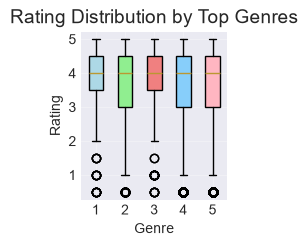

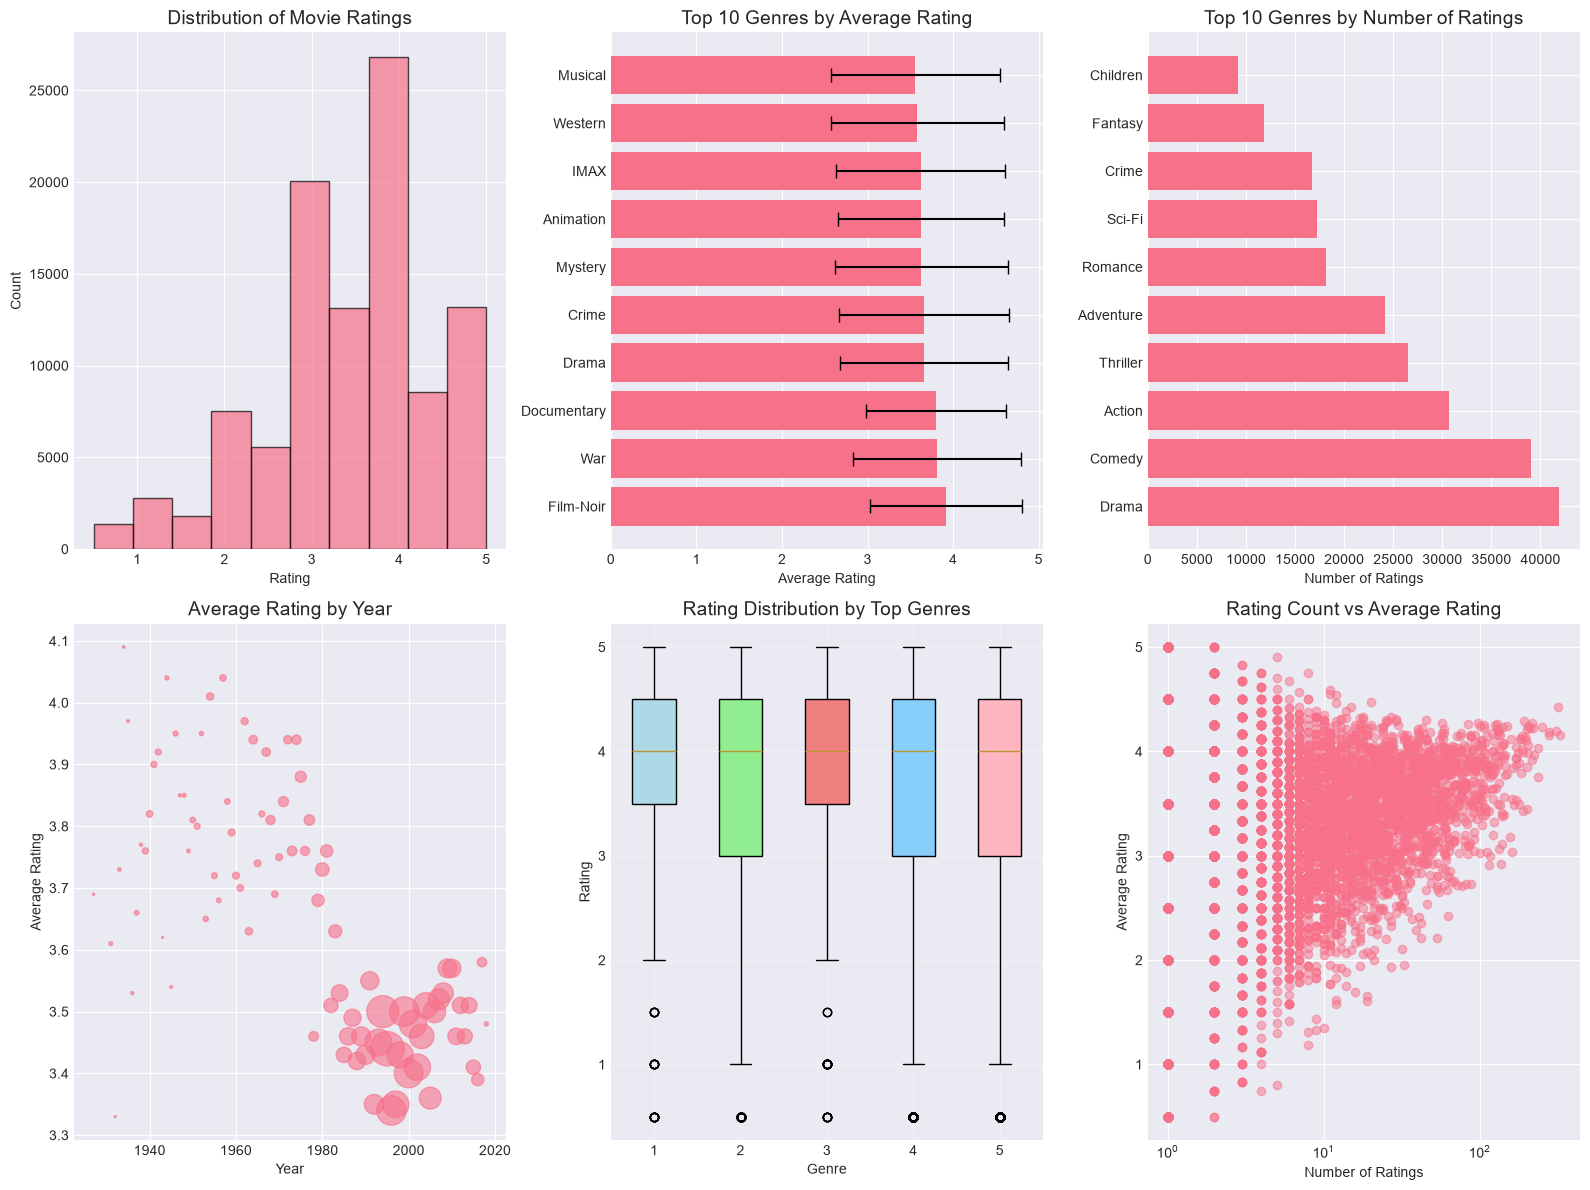

In [66]:
# Create a figure with subplots
fig = plt.figure(figsize=(16, 12))

# 1. Rating Distribution
ax1 = plt.subplot(2, 3, 1)
df['rating'].hist(bins=10, edgecolor='black', alpha=0.7)
ax1.set_title('Distribution of Movie Ratings', fontsize=14)
ax1.set_xlabel('Rating')
ax1.set_ylabel('Count')

# 2. Genre Average Ratings
ax2 = plt.subplot(2, 3, 2)
genre_stats_top = genre_stats.head(10)
ax2.barh(genre_stats_top.index, genre_stats_top['avg_rating'], 
         xerr=genre_stats_top['std_rating'], capsize=5)
ax2.set_title('Top 10 Genres by Average Rating', fontsize=14)
ax2.set_xlabel('Average Rating')

# 3. Genre Popularity
ax3 = plt.subplot(2, 3, 3)
genre_counts = df_genres['genres'].value_counts().head(10)
ax3.barh(genre_counts.index, genre_counts.values)
ax3.set_title('Top 10 Genres by Number of Ratings', fontsize=14)
ax3.set_xlabel('Number of Ratings')

# 4. Ratings Over Years
ax4 = plt.subplot(2, 3, 4)
years_to_plot = yearly_stats.reset_index()
ax4.scatter(years_to_plot['year'], years_to_plot['avg_rating'], 
           s=years_to_plot['num_ratings']/10, alpha=0.6)
ax4.set_title('Average Rating by Year', fontsize=14)
ax4.set_xlabel('Year')
ax4.set_ylabel('Average Rating')

# 5. Boxplot of Ratings by Genre (Top 5)
ax5 = plt.subplot(2, 3, 5)
# Fix the boxplot section (subplot 5)
ax5 = plt.subplot(2, 3, 5)
# Convert top_genres index to a list first
top_genres_list = genre_stats.head(5).index.tolist()
# Now this will work properly
genre_box_data = [df_genres[df_genres['genres'] == g]['rating'] for g in top_genres_list]
# Create boxplot
bp = ax5.boxplot(genre_box_data, label=top_genres_list, patch_artist=True)
# Customize boxplot colors
colors = ['lightblue', 'lightgreen', 'lightcoral', 'lightskyblue', 'lightpink']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
ax5.set_title('Rating Distribution by Top Genres', fontsize=14)
ax5.set_xlabel('Genre')
ax5.set_ylabel('Rating')
ax5.grid(True, alpha=0.3)

# 6. Correlation between Rating Count and Average Rating
ax6 = plt.subplot(2, 3, 6)
ax6.scatter(movie_stats['num_ratings'], movie_stats['avg_rating'], alpha=0.5)
ax6.set_xlabel('Number of Ratings')
ax6.set_ylabel('Average Rating')
ax6.set_title('Rating Count vs Average Rating', fontsize=14)
ax6.set_xscale('log')

plt.tight_layout()
plt.savefig('movie_ratings_analysis.png', dpi=300, bbox_inches='tight')
plt.show()